# Australia Wildfire Analysis and Dashboard

Exploratory visual analysis of 26,406 wildfire records across 7 Australian regions (Matplotlib, Seaborn, Folium) and an interactive Dash + Plotly dashboard.


# WILDFIRE ACTIVITIES IN AUSTRALIA

# Part 1 — Analyzing the wildfire activities in Australia

Dataset: historical wildfire records for Australia (from 2005), one row per region per day.

**Columns:** `Region`, `Date`, `Estimated_fire_area`, `Mean_estimated_fire_brightness`, `Mean_estimated_fire_radiative_power`, `Mean_confidence`, `Std_confidence`, `Var_confidence`, `Count`, `Replaced`.

Libraries used: **Matplotlib, Seaborn, Pandas and Folium**.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
%matplotlib inline

# Load the historical wildfire dataset (IBM mirror)
wild_url = (
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Historical_Wildfires.csv"
)
df_wild = pd.read_csv(wild_url)

# Parse the Date column and derive Year / Month helpers used throughout Part 1
df_wild["Date"] = pd.to_datetime(df_wild["Date"])
df_wild["Year"] = df_wild["Date"].dt.year
df_wild["Month"] = df_wild["Date"].dt.month

print("Shape:", df_wild.shape)
print("Regions:", df_wild["Region"].unique().tolist())
df_wild.head()


Shape: (26406, 12)
Regions: ['NSW', 'NT', 'QL', 'SA', 'TA', 'VI', 'WA']


,Region,Date,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Mean_confidence,Std_confidence,Var_confidence,Count,Replaced,Year,Month
0,NSW,2005-01-04,8.68000,312.266667,42.400000,78.666667,2.886751,8.333333,3,R,2005,1
1,NSW,2005-01-05,16.61125,322.475000,62.362500,85.500000,8.088793,65.428571,8,R,2005,1
2,NSW,2005-01-06,5.52000,325.266667,38.400000,78.333333,3.214550,10.333333,3,R,2005,1
3,NSW,2005-01-07,6.26400,313.870000,33.800000,92.200000,7.529940,56.700000,5,R,2005,1
4,NSW,2005-01-08,5.40000,337.383333,122.533333,91.000000,7.937254,63.000000,3,R,2005,1


## TASK 1.1 — Change in average estimated fire area over time (line chart, pandas)

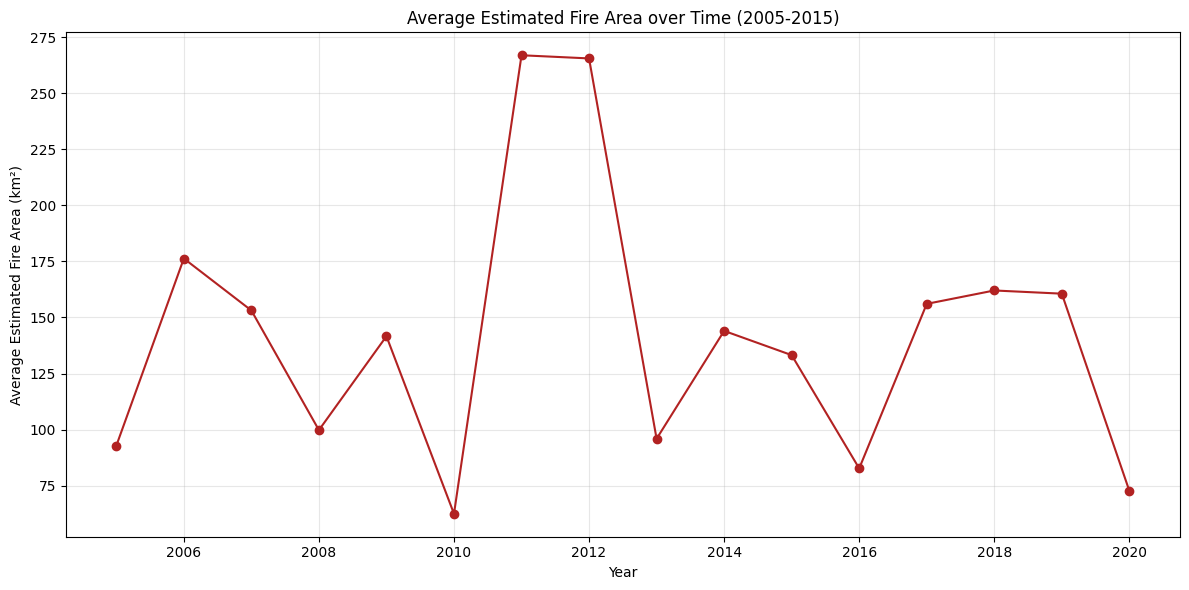

In [59]:
# Average estimated fire area per year across all regions
df_year = df_wild.groupby("Year")["Estimated_fire_area"].mean()

plt.figure(figsize=(12, 6))
df_year.plot(kind="line", marker="o", color="firebrick")
plt.title("Average Estimated Fire Area over Time (2005-2015)")
plt.xlabel("Year")
plt.ylabel("Average Estimated Fire Area (km²)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## TASK 1.2 — Estimated fire area over month (monthly grouping, line chart)

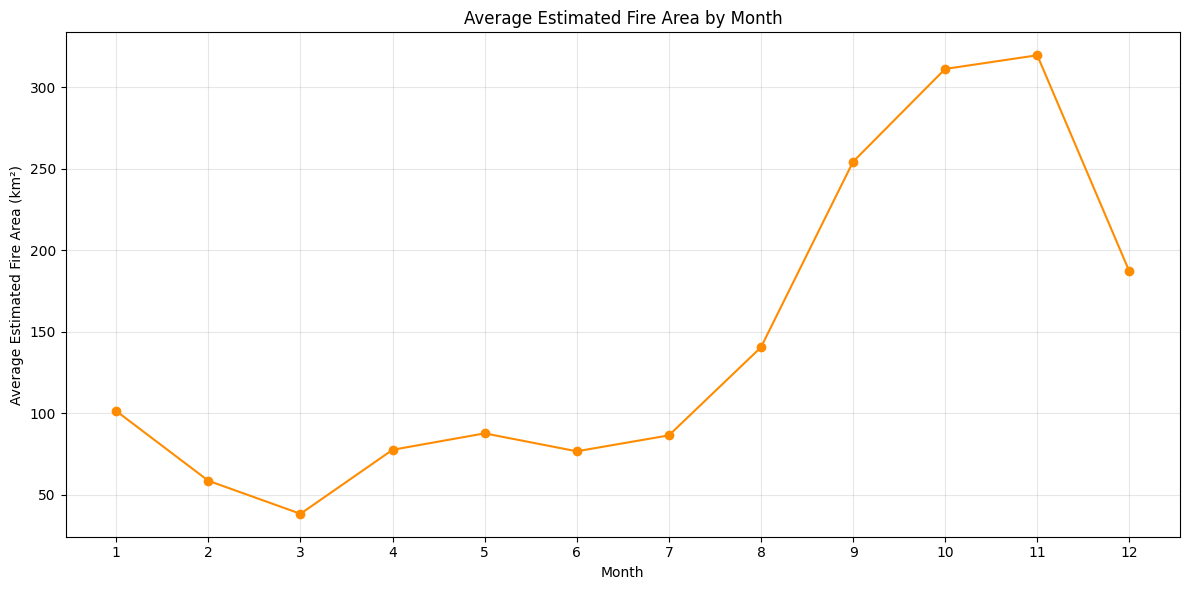

In [60]:
# Average estimated fire area per calendar month (seasonality across all years)
df_month = df_wild.groupby("Month")["Estimated_fire_area"].mean()

plt.figure(figsize=(12, 6))
df_month.plot(kind="line", marker="o", color="darkorange")
plt.title("Average Estimated Fire Area by Month")
plt.xlabel("Month")
plt.ylabel("Average Estimated Fire Area (km²)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## TASK 1.3 — Distribution of mean estimated fire brightness across regions (seaborn barplot)

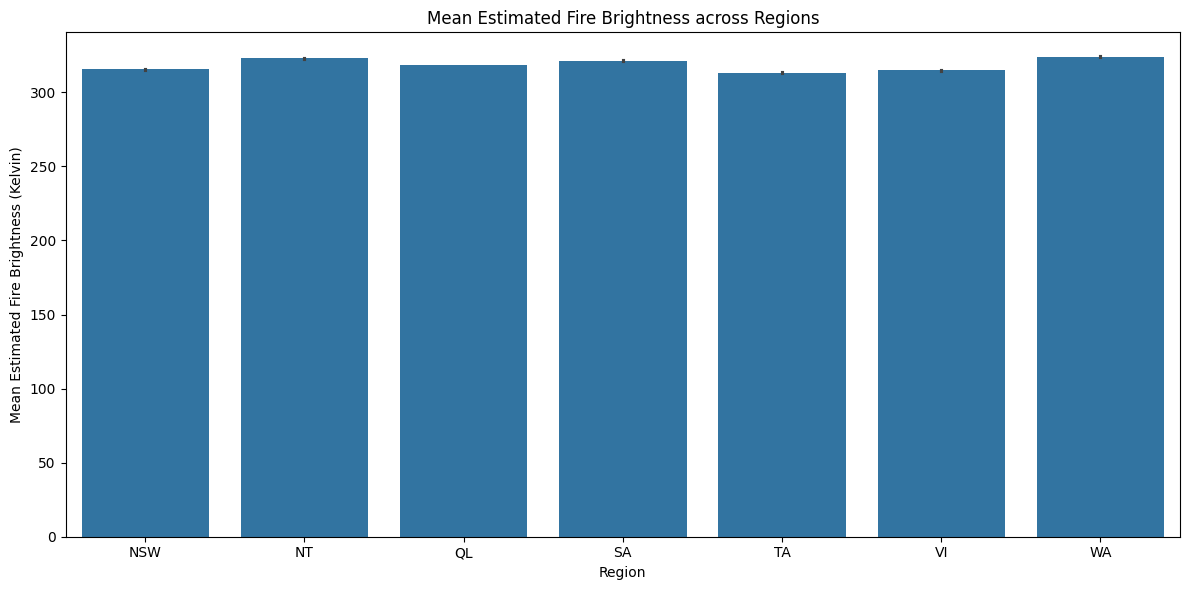

In [61]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_wild, x="Region", y="Mean_estimated_fire_brightness")
plt.title("Mean Estimated Fire Brightness across Regions")
plt.xlabel("Region")
plt.ylabel("Mean Estimated Fire Brightness (Kelvin)")
plt.tight_layout()
plt.show()


## TASK 1.4 — Portion of pixel count for vegetation fires across regions (pie chart)

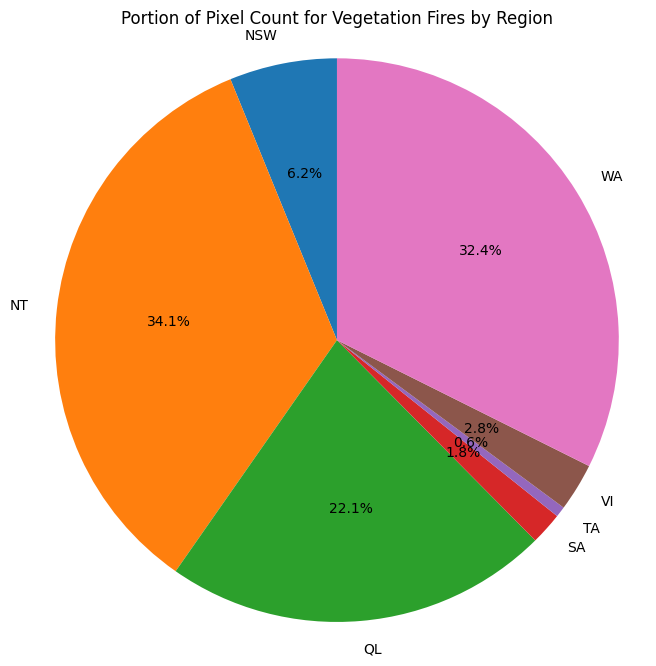

In [62]:
# Total pixel count per region
df_region = df_wild.groupby("Region")["Count"].sum()

plt.figure(figsize=(8, 8))
plt.pie(df_region, labels=df_region.index, autopct="%1.1f%%", startangle=90)
plt.title("Portion of Pixel Count for Vegetation Fires by Region")
plt.axis("equal")
plt.show()


## TASK 1.5 — Customized pie chart (percentages moved outside, explicit legend)

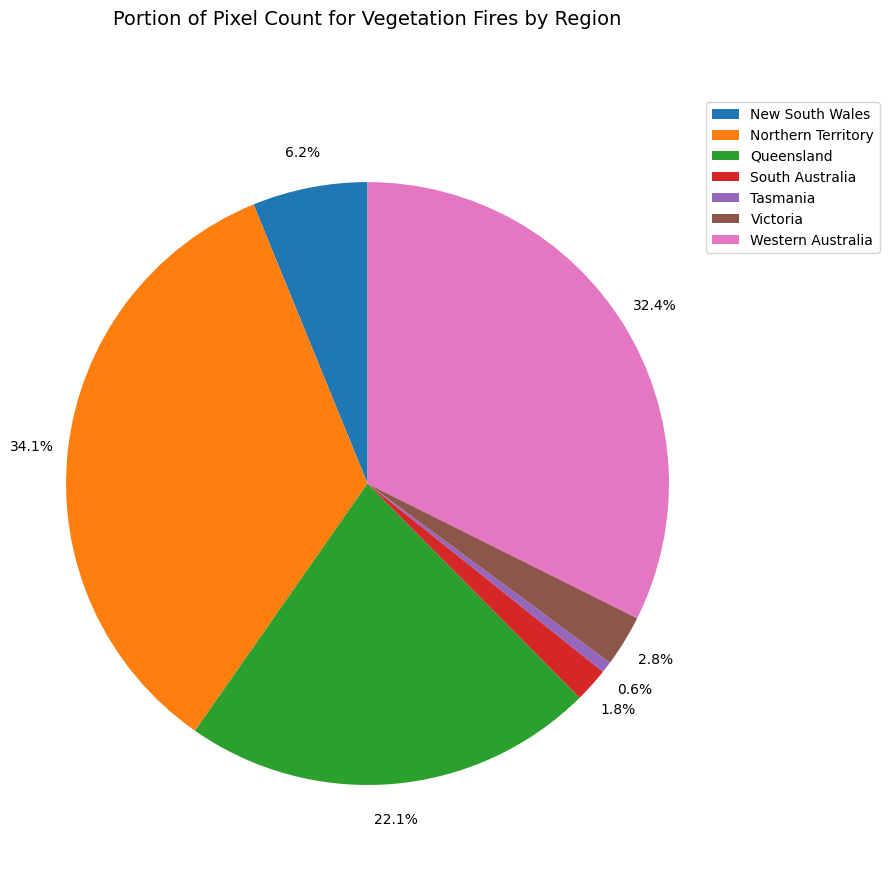

In [63]:
region_names = ["New South Wales", "Northern Territory", "Queensland",
                "South Australia", "Tasmania", "Victoria", "Western Australia"]

plt.figure(figsize=(9, 9))
plt.pie(
    df_region,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=1.12,
)
plt.title("Portion of Pixel Count for Vegetation Fires by Region", y=1.08, fontsize=14)
plt.legend(labels=region_names, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.axis("equal")
plt.tight_layout()
plt.show()


## TASK 1.6 — Histogram of mean estimated fire brightness (Matplotlib)

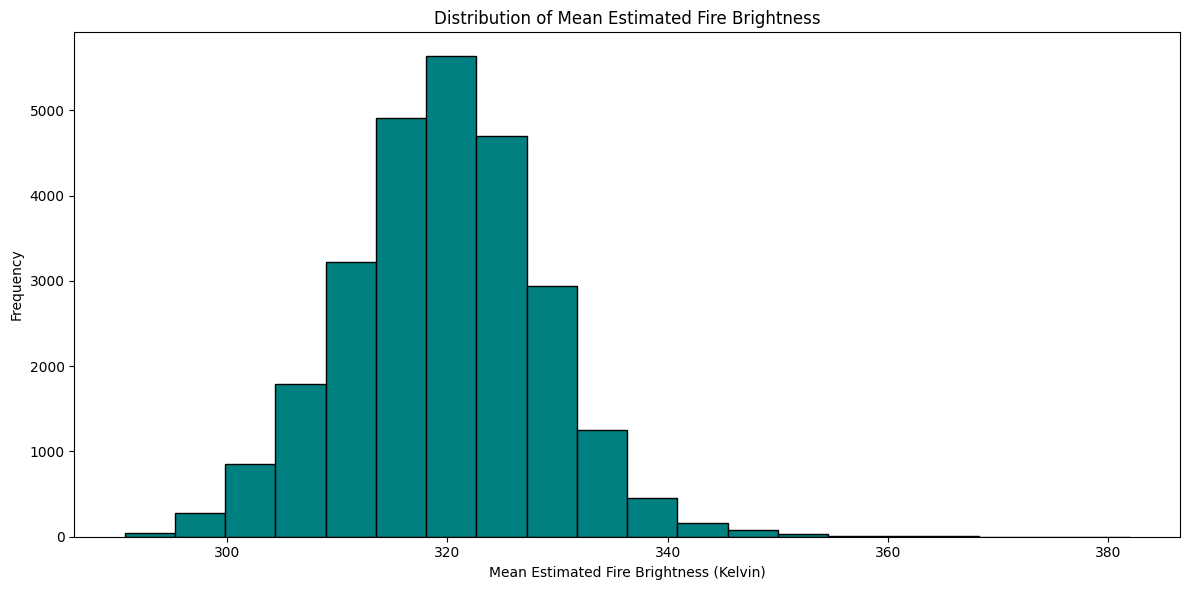

In [64]:
plt.figure(figsize=(12, 6))
plt.hist(df_wild["Mean_estimated_fire_brightness"], bins=20, color="teal", edgecolor="black")
plt.title("Distribution of Mean Estimated Fire Brightness")
plt.xlabel("Mean Estimated Fire Brightness (Kelvin)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## TASK 1.7 — Distribution of fire brightness across regions (seaborn histogram, hue=Region)

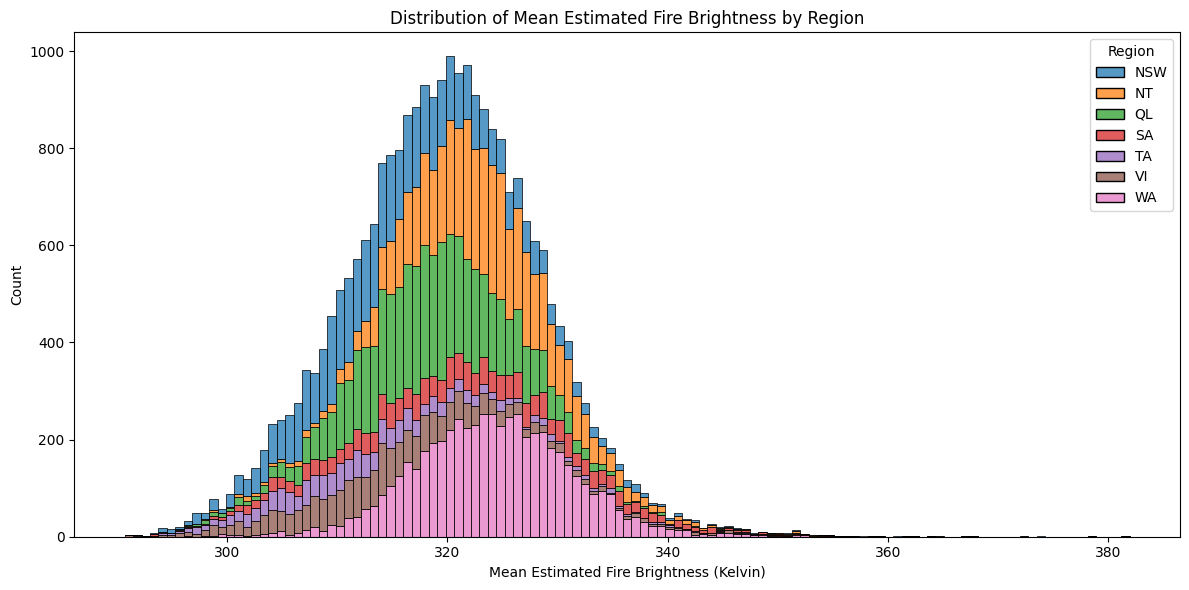

In [65]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df_wild, x="Mean_estimated_fire_brightness", hue="Region", multiple="stack")
plt.title("Distribution of Mean Estimated Fire Brightness by Region")
plt.xlabel("Mean Estimated Fire Brightness (Kelvin)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


## TASK 1.8 — Correlation between mean fire radiative power and mean confidence (scatter plot)

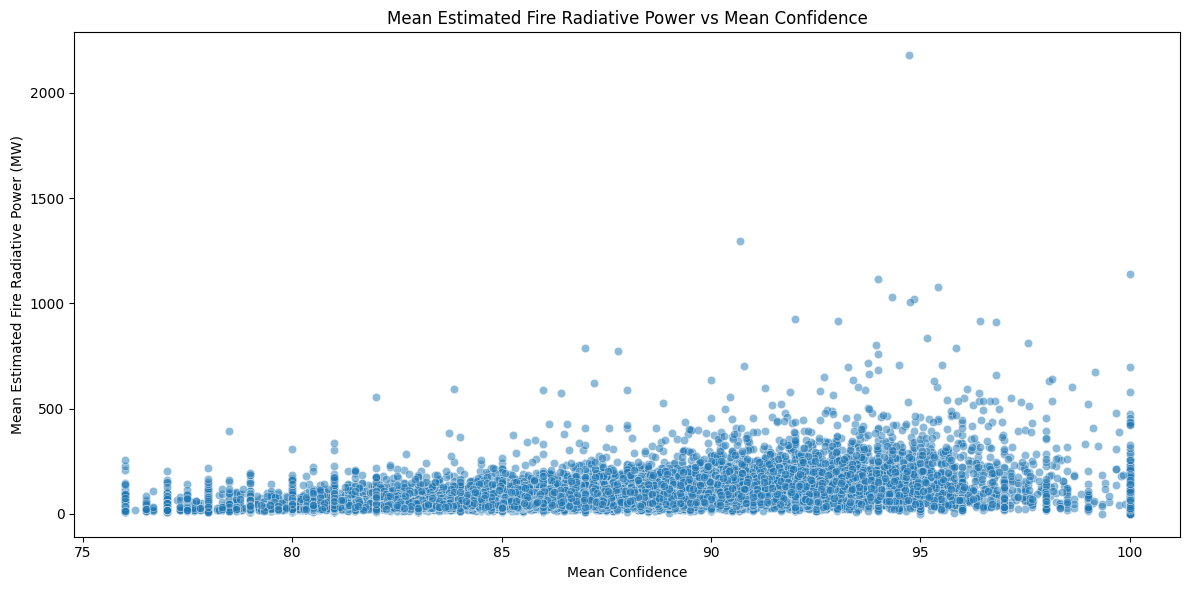

In [66]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_wild,
    x="Mean_confidence",
    y="Mean_estimated_fire_radiative_power",
    alpha=0.5,
)
plt.title("Mean Estimated Fire Radiative Power vs Mean Confidence")
plt.xlabel("Mean Confidence")
plt.ylabel("Mean Estimated Fire Radiative Power (MW)")
plt.tight_layout()
plt.show()


## TASK 1.9 — Mark the seven wildfire regions on a map of Australia (Folium)

In [67]:
# Approximate centroid coordinates for each of the 7 wildfire regions
region_coords = {
    "NSW": (-31.8759835, 145.612793),   # New South Wales
    "NT":  (-19.491411, 132.550964),    # Northern Territory
    "QL":  (-22.575197, 144.0848),      # Queensland
    "SA":  (-30.000233, 136.209152),    # South Australia
    "TA":  (-42.035067, 146.636689),    # Tasmania
    "VI":  (-36.5986096, 144.6780052),  # Victoria
    "WA":  (-25.2303005, 121.0187246),  # Western Australia
}

# Center the map on Australia
aus_map = folium.Map(location=[-25.0, 133.0], zoom_start=4)

for region, (lat, lon) in region_coords.items():
    folium.Marker(
        location=[lat, lon],
        popup=region,
        tooltip=region,
        icon=folium.Icon(color="red", icon="fire", prefix="fa"),
    ).add_to(aus_map)

aus_map


# Part 2 — Dashboard (Dash + Plotly)

Interactive dashboard where the user selects a **Region** (radio items) and a **Year** (dropdown). Based on the selection it displays:

- **Pie Chart** — Monthly Average Estimated Fire Area
- **Bar Chart** — Monthly Average Count of Pixels for Presumed Vegetation Fires

Run the cell below, then open the printed local URL (e.g. `http://127.0.0.1:8050`) in a browser. To stop the server, interrupt the kernel.

In [29]:
import pandas as pd
import plotly.express as px
import dash
from dash import dcc, html
from dash.dependencies import Input, Output

# Load the wildfire data for the dashboard
df_dash = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Historical_Wildfires.csv"
)
df_dash["Date"] = pd.to_datetime(df_dash["Date"])
df_dash["Year"] = df_dash["Date"].dt.year
df_dash["Month"] = df_dash["Date"].dt.month_name()

app = dash.Dash(__name__)

# TASK 2.1: dashboard title
app.layout = html.Div(children=[
    html.H1(
        "Australia Wildfire Dashboard",
        style={"textAlign": "center", "color": "#503D36", "font-size": 26},
    ),
    # TASK 2.2: radio items (Region) and dropdown (Year)
    html.Div([
        html.Div([
            html.H2("Select Region:", style={"margin-right": "2em"}),
            dcc.RadioItems(
                options=[
                    {"label": "New South Wales", "value": "NSW"},
                    {"label": "Northern Territory", "value": "NT"},
                    {"label": "Queensland", "value": "QL"},
                    {"label": "South Australia", "value": "SA"},
                    {"label": "Tasmania", "value": "TA"},
                    {"label": "Victoria", "value": "VI"},
                    {"label": "Western Australia", "value": "WA"},
                ],
                value="NSW",
                id="region",
                inline=True,
            ),
        ]),
        html.Div([
            html.H2("Select Year:", style={"margin-right": "2em"}),
            dcc.Dropdown(
                options=[{"label": y, "value": y} for y in sorted(df_dash["Year"].unique())],
                value=2005,
                id="year",
            ),
        ]),
        # TASK 2.3: two output divisions
        html.Div([
            html.Div([], id="plot1"),
            html.Div([], id="plot2"),
        ], style={"display": "flex"}),
    ]),
])


# TASK 2.4: output and input components
@app.callback(
    [Output(component_id="plot1", component_property="children"),
     Output(component_id="plot2", component_property="children")],
    [Input(component_id="region", component_property="value"),
     Input(component_id="year", component_property="value")],
)
# TASK 2.5: callback function
def reg_year_display(input_region, input_year):
    region_data = df_dash[df_dash["Region"] == input_region]
    y_r_data = region_data[region_data["Year"] == input_year]

    # Pie chart: monthly average estimated fire area
    est_data = y_r_data.groupby("Month")["Estimated_fire_area"].mean().reset_index()
    fig1 = px.pie(
        est_data, values="Estimated_fire_area", names="Month",
        title=f"{input_region} : Monthly Average Estimated Fire Area in {input_year}",
    )

    # Bar chart: monthly average pixel count
    veg_data = y_r_data.groupby("Month")["Count"].mean().reset_index()
    fig2 = px.bar(
        veg_data, x="Month", y="Count",
        title=f"{input_region} : Average Count of Pixels for Presumed Vegetation Fires in {input_year}",
    )

    return [dcc.Graph(figure=fig1), dcc.Graph(figure=fig2)]


if __name__ == "__main__":
    app.run(debug=False)
